## Часть B: StyleGAN-подобная модель

Задача: реализовать упрощённую StyleGAN-like архитектуру (generator + discriminator + mapping network), обучить её на выбранном домене (здесь — тот же датасет лиц CelebA) и показать:

- генерацию новых изображений;
- интерполяцию в latent space;
- style mixing (управляемое комбинирование стилей).

Архитектуры должны быть реализованы самостоятельно, без использования готовых реализаций. Ноутбук сдаётся **с выполненными ячейками**.

**Про вычислительные ресурсы.** Эталонные картинки ниже получены на 128×128 примерно за 70 эпох с R1-регуляризацией: это больше 14 часов на GPU. Такого качества мы не ждём. Можно обучать на 64×64 и меньше эпох — оценивается корректность реализации и разбор результатов, а не фотореалистичность.

*По желанию:* посчитайте FID (как на семинаре) для нескольких чекпойнтов и сравните с тем, что видно глазами.

### Часть B. Шаг 1: Настройка TensorBoard и гиперпараметров для GAN

Что сделать: создать `SummaryWriter` для StyleGAN-подобной модели и задать базовые гиперпараметры.

Ожидается: отдельный лог для GAN и разумные параметры обучения.

In [1]:
import os
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

from torch.utils.tensorboard import SummaryWriter

# Настройка устройства
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Используемое устройство: {device}')

# YOUR CODE IS HERE
import random
import time
from pathlib import Path
from torchvision.utils import make_grid

output_dir_stylegan = Path(os.environ.get("GAN_OUTPUT_DIR", "artifacts/stylegan"))
output_dir_stylegan.mkdir(parents=True, exist_ok=True)

log_dir_stylegan = output_dir_stylegan / "tensorboard"
writer_stylegan = SummaryWriter(log_dir_stylegan)
print(f'TensorBoard StyleGAN логируется в: {log_dir_stylegan}')

# при необходимости добавьте фиксацию seed, детерминизм и другие настройки
# YOUR CODE IS HERE
seed_gan = int(os.environ.get("GAN_SEED", "42"))
random.seed(seed_gan)
np.random.seed(seed_gan)
torch.manual_seed(seed_gan)
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

latent_dim_gan = 128
num_channels = 3

Используемое устройство: cuda
TensorBoard StyleGAN логируется в: artifacts/stylegan/tensorboard


### Часть B. Шаг 2: Загрузка и предобработка датасета лиц

Что сделать: задать трансформации (crop, resize, normalize), создать датасет CelebA и `DataLoader`.

**Где взять данные.** Нужна версия *Align&Cropped* (`img_align_celeba`, ~200 тыс. изображений 178×218) и файлы разметки. Источники: официальная страница https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html или зеркало на Kaggle `jessicali9530/celeba-dataset`. Автоскачивание `torchvision.datasets.CelebA(download=True)` часто падает из-за лимитов Google Drive.

Положите всё в одну папку:

```
data/celeba/CelebA/
├── img_align_celeba/        # 000001.jpg, 000002.jpg, ...
├── list_attr_celeba.txt     # или list_attr_celeba.csv (Kaggle)
└── list_eval_partition.txt  # или list_eval_partition.csv (Kaggle)
```

Ниже дан готовый класс `CelebAWithAttrs`: он читает и `.txt`, и `.csv` и сам находит вложенную папку `img_align_celeba/img_align_celeba` из архива Kaggle. Датасет возвращает пары `(image, attrs)`, атрибуты приведены к значениям **{0, 1}** (в исходных файлах {−1, 1}). Также доступны `dataset.attr_names` (список из 40 имён) и `dataset.attr` (тензор `[N, 40]`). Последующие ячейки ноутбука рассчитаны именно на этот интерфейс.

Ожидается: корректный `DataLoader` с батчами `(images, attrs)`.

In [2]:
import csv
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class CelebAWithAttrs(Dataset):
    """CelebA (Align&Cropped) с атрибутами.

    root — папка, где лежат img_align_celeba/ и файлы разметки (.txt или .csv).
    split — 'train', 'valid', 'test' или 'all' (по list_eval_partition).
    Возвращает (image, attrs), attrs — float-тензор из 0 и 1 длины 40.
    """

    SPLITS = {"train": 0, "valid": 1, "test": 2}

    def __init__(self, root, split="train", transform=None):
        root = Path(root)
        self.transform = transform

        img_dir = root / "img_align_celeba"
        if (img_dir / "img_align_celeba").is_dir():  # архив с Kaggle
            img_dir = img_dir / "img_align_celeba"
        if not img_dir.is_dir():
            raise FileNotFoundError(f"Не найдена папка с изображениями: {img_dir}")
        self.img_dir = img_dir

        self.attr_names, attrs = self._read_attrs(root)
        partition = self._read_partition(root)

        if split == "all":
            files = list(attrs)
        else:
            files = [f for f in attrs if partition[f] == self.SPLITS[split]]
        self.filenames = files
        self.attr = torch.tensor([attrs[f] for f in files], dtype=torch.long)
        self.attr = (self.attr + 1) // 2  # {-1, 1} -> {0, 1}

    @staticmethod
    def _read_attrs(root):
        txt, csv_path = root / "list_attr_celeba.txt", root / "list_attr_celeba.csv"
        attrs = {}
        if txt.exists():
            with open(txt) as f:
                lines = f.read().splitlines()
            names = lines[1].split()
            for line in lines[2:]:
                parts = line.split()
                attrs[parts[0]] = [int(v) for v in parts[1:]]
        elif csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                names = next(reader)[1:]
                for row in reader:
                    attrs[row[0]] = [int(v) for v in row[1:]]
        else:
            raise FileNotFoundError(f"Не найден list_attr_celeba.txt/.csv в {root}")
        return names, attrs

    @staticmethod
    def _read_partition(root):
        txt, csv_path = root / "list_eval_partition.txt", root / "list_eval_partition.csv"
        if txt.exists():
            with open(txt) as f:
                return {p[0]: int(p[1]) for p in (l.split() for l in f) if p}
        if csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                next(reader)
                return {row[0]: int(row[1]) for row in reader}
        raise FileNotFoundError(f"Не найден list_eval_partition.txt/.csv в {root}")

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        image = Image.open(self.img_dir / self.filenames[idx]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, self.attr[idx].float()

In [3]:
# Исходные кадры 178×218. Сначала вырезаем квадрат с лицом, потом уменьшаем:
# Resize((H, W)) с разными сторонами растянул бы лица.
# При нехватке GPU замените 128 на 64.
image_size = int(os.environ.get("GAN_IMAGE_SIZE", "64"))

transform = transforms.Compose([
    transforms.CenterCrop(140),
    transforms.Resize(image_size),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# YOUR CODE IS HERE
# Пример: dataset = CelebAWithAttrs(root='data/celeba/CelebA', split='train', transform=transform)

dataset = CelebAWithAttrs(
    root=os.environ.get("CELEBA_ROOT", "data/celeba/CelebA"),
    split="train",
    transform=transform,
)
max_images_gan = int(os.environ.get("GAN_MAX_IMAGES", "0"))
data_rng = torch.Generator().manual_seed(seed_gan)
if 0 < max_images_gan < len(dataset):
    sample_indices = torch.randperm(len(dataset), generator=data_rng)[:max_images_gan].tolist()
    dataset = torch.utils.data.Subset(dataset, sample_indices)

gan_workers = int(os.environ.get("GAN_WORKERS", "4" if device.type == "cuda" else "0"))
dataloader = DataLoader(
    dataset,
    batch_size=int(os.environ.get("GAN_BATCH_SIZE", "64")),
    shuffle=True,
    num_workers=gan_workers,
    persistent_workers=gan_workers > 0,
    pin_memory=device.type == "cuda",
    generator=data_rng,
)

print(f'Размер датасета: {len(dataset)} изображений')
print(f'Количество батчей: {len(dataloader)}')

Размер датасета: 162770 изображений
Количество батчей: 2544


### Часть B. Шаг 3: Реализация генератора, дискриминатора и mapping-сети

Что сделать: реализовать классы `MappingNetwork`, `StyledBlock`, `StyleGenerator` и `StyleDiscriminator`.

**Обязательный интерфейс** (на него рассчитаны шаги 5 и 6):

- латентный вектор `z` имеет форму `[B, latent_dim_gan]` (двумерный, без `1×1`);
- `G.mapping(z)` → `w` формы `[B, w_dim]`;
- `G.num_ws` — число стилевых входов синтеза (по одному на `StyledBlock`), не меньше 4;
- `G.make_ws(z)` → `ws` формы `[B, G.num_ws, w_dim]` (один и тот же `w`, повторённый `num_ws` раз);
- `G.forward_from_ws(ws)` → изображения `[B, 3, image_size, image_size]` в `[-1, 1]`; блок `i` использует `ws[:, i]`;
- `G(z)` = `G.forward_from_ws(G.make_ws(z))`;
- `D(x)` → логиты формы `[B, 1]`.

Ожидается: рабочая генерация изображений заданного размера.

In [4]:
class MappingNetwork(nn.Module):
    """z [B, z_dim] -> w [B, w_dim]"""
    def __init__(self, z_dim, w_dim):
        super().__init__()
        # YOUR CODE IS HERE
        self.layers = nn.Sequential(
            nn.Linear(z_dim, w_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(w_dim, w_dim),
            nn.LeakyReLU(0.2),
            nn.Linear(w_dim, w_dim),
        )

    def forward(self, z):
        # YOUR CODE IS HERE
        z = z * torch.rsqrt(z.square().mean(dim=1, keepdim=True) + 1e-8)
        return self.layers(z)


class StyledBlock(nn.Module):
    """Свёрточный блок, модулируемый стилем w [B, w_dim]"""
    def __init__(self, in_channels, out_channels, w_dim):
        super().__init__()
        # YOUR CODE IS HERE
        self.conv = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.norm = nn.InstanceNorm2d(out_channels)
        self.affine = nn.Linear(w_dim, 2 * out_channels)
        nn.init.zeros_(self.affine.bias)

    def forward(self, x, w):
        # YOUR CODE IS HERE
        x = self.norm(self.conv(x))
        scale, bias = self.affine(w).chunk(2, dim=1)
        x = x * (1 + scale[:, :, None, None]) + bias[:, :, None, None]
        return F.leaky_relu(x, negative_slope=0.2)


class StyleGenerator(nn.Module):
    def __init__(self, z_dim, w_dim, img_channels=3):
        super().__init__()
        self.mapping = MappingNetwork(z_dim, w_dim)
        # YOUR CODE IS HERE
        if image_size not in (32, 64, 128):
            raise ValueError("GAN_IMAGE_SIZE должен быть 32, 64 или 128.")
        channels_by_size = {4: 128, 8: 128, 16: 96, 32: 64, 64: 32, 128: 16}
        channels = [channels for size, channels in channels_by_size.items() if size <= image_size]
        self.constant = nn.Parameter(torch.randn(1, channels[0], 4, 4))
        self.blocks = nn.ModuleList(
            StyledBlock(in_channels, out_channels, w_dim)
            for in_channels, out_channels in zip([channels[0], *channels[:-1]], channels)
        )
        self.to_rgb = nn.Conv2d(channels[-1], img_channels, 1)
        self.num_ws = len(self.blocks)  # число StyledBlock-ов, >= 4

    def make_ws(self, z):
        # [B, z_dim] -> [B, num_ws, w_dim]
        # YOUR CODE IS HERE
        return self.mapping(z).unsqueeze(1).expand(-1, self.num_ws, -1)

    def forward_from_ws(self, ws):
        # [B, num_ws, w_dim] -> [B, 3, image_size, image_size]
        # YOUR CODE IS HERE
        x = self.constant.expand(ws.shape[0], -1, -1, -1)
        for index, block in enumerate(self.blocks):
            if index:
                x = F.interpolate(x, scale_factor=2, mode="nearest")
            x = block(x, ws[:, index])
        return torch.tanh(self.to_rgb(x))

    def forward(self, z):
        return self.forward_from_ws(self.make_ws(z))


class StyleDiscriminator(nn.Module):
    """Изображение [B, 3, H, W] -> логит [B, 1]"""
    def __init__(self, img_channels=3):
        super().__init__()
        # YOUR CODE IS HERE
        channels_by_size = {128: 16, 64: 32, 32: 64, 16: 96, 8: 128, 4: 128}
        self.from_rgb = nn.Conv2d(img_channels, channels_by_size[image_size], 1)
        layers = []
        size = image_size
        while size > 4:
            in_channels = channels_by_size[size]
            out_channels = channels_by_size[size // 2]
            layers.extend([
                nn.Conv2d(in_channels, out_channels, 4, stride=2, padding=1),
                nn.LeakyReLU(0.2),
            ])
            size //= 2
        self.blocks = nn.Sequential(*layers)
        final_channels = channels_by_size[4]
        self.classifier = nn.Sequential(
            nn.Conv2d(final_channels + 1, final_channels, 3, padding=1),
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(final_channels * 4 * 4, 1),
        )

    def forward(self, x):
        # YOUR CODE IS HERE
        x = self.blocks(F.leaky_relu(self.from_rgb(x), negative_slope=0.2))
        batch_std = (x.var(dim=0, unbiased=False) + 1e-8).sqrt().mean()
        batch_std = batch_std.reshape(1, 1, 1, 1).expand(x.size(0), 1, x.size(2), x.size(3))
        return self.classifier(torch.cat((x, batch_std), dim=1))

### Часть B. Шаг 4: Обучение GAN с логированием

Что сделать: реализовать цикл обучения GAN (обучение D и G) с логированием лоссов и изображений в TensorBoard.

Ожидается: осмысленные графики лоссов и примеры сгенерированных изображений.

In [5]:
# YOUR CODE IS HERE
w_dim = 128
r1_gamma = float(os.environ.get("GAN_R1_GAMMA", "0.5"))
r1_interval = 16
max_steps_per_epoch = int(os.environ.get("GAN_MAX_STEPS_PER_EPOCH", "0"))
train_seconds_gan = float(os.environ.get("GAN_TRAIN_SECONDS", "0"))
train_batches = min(len(dataloader), max_steps_per_epoch) if max_steps_per_epoch > 0 else len(dataloader)

G = StyleGenerator(latent_dim_gan, w_dim, num_channels).to(device)
D = StyleDiscriminator(num_channels).to(device)

# Проверка интерфейса
with torch.no_grad():
    z_check = torch.randn(4, latent_dim_gan, device=device)
    ws_check = G.make_ws(z_check)
    img_check = G(z_check)
assert G.num_ws >= 4
assert G.mapping(z_check).dim() == 2
assert ws_check.shape[:2] == (4, G.num_ws)
assert img_check.shape == (4, num_channels, image_size, image_size), img_check.shape
assert D(img_check).shape == (4, 1)
print('Интерфейс G и D в порядке.')

optimizer_G = optim.Adam(G.parameters(), lr=0.0003, betas=(0.0, 0.99))
optimizer_D = optim.Adam(D.parameters(), lr=0.0003, betas=(0.0, 0.99))

num_epochs_gan = int(os.environ.get("GAN_EPOCHS", "15"))
if num_epochs_gan < 1:
    raise ValueError("GAN_EPOCHS должен быть положительным.")

# для удобного логгирования и просмотра динамики обучения можно зафиксировать некоторый z
fixed_z = torch.randn(16, latent_dim_gan, device=device)

def discriminator_loss(real_logits, fake_logits):
    return F.softplus(-real_logits).mean() + F.softplus(fake_logits).mean()

def generator_loss(fake_logits):
    return F.softplus(-fake_logits).mean()

def generate_training_batch(batch_size):
    z = torch.randn(batch_size, latent_dim_gan, device=device)
    if random.random() >= 0.5:
        return G(z)
    crossover = random.randrange(1, G.num_ws)
    other_z = torch.randn_like(z)
    ws = torch.cat((G.make_ws(z)[:, :crossover], G.make_ws(other_z)[:, crossover:]), dim=1)
    return G.forward_from_ws(ws)

epoch_start_step = 0
train_started_gan = time.monotonic()
global_step = 0

for epoch in range(num_epochs_gan):
    G.train()
    D.train()

    total_g = 0.0
    total_d = 0.0

    for real_images, _ in dataloader:

        # Обучение дискриминатора
        # YOUR CODE IS HERE
        epoch_step = global_step - epoch_start_step
        if epoch_step >= train_batches:
            break
        if global_step and train_seconds_gan > 0 and time.monotonic() - train_started_gan >= train_seconds_gan:
            break

        D.requires_grad_(True)
        optimizer_D.zero_grad(set_to_none=True)
        use_r1 = r1_gamma > 0 and (global_step + 1) % r1_interval == 0
        real_images = real_images.to(device, non_blocking=True).requires_grad_(use_r1)
        with torch.no_grad():
            fake_images = generate_training_batch(real_images.size(0))
        real_logits = D(real_images)
        loss_d = discriminator_loss(real_logits, D(fake_images))
        if use_r1:
            real_grad, = torch.autograd.grad(real_logits.sum(), real_images, create_graph=True)
            r1 = real_grad.square().flatten(1).sum(dim=1).mean()
            loss_d = loss_d + (r1_gamma * r1_interval / 2) * r1
            writer_stylegan.add_scalar("train/r1", r1.item(), global_step + 1)

        loss_d.backward()
        optimizer_D.step()

        # Обучение генератора
        # YOUR CODE IS HERE
        D.requires_grad_(False)
        optimizer_G.zero_grad(set_to_none=True)
        loss_g = generator_loss(D(generate_training_batch(real_images.size(0))))

        global_step += 1
        g_value, d_value = torch.stack([loss_g.detach(), loss_d.detach()]).tolist()
        total_g += g_value
        total_d += d_value
        if global_step == 1 or global_step % 50 == 0:
            writer_stylegan.add_scalar("train/generator", g_value, global_step)
            writer_stylegan.add_scalar("train/discriminator", d_value, global_step)
        if global_step == 1 or global_step % 250 == 0:
            elapsed = time.monotonic() - train_started_gan
            print(f"Шаг {global_step}, {elapsed:.0f} с: G={g_value:.3f}, D={d_value:.3f}", flush=True)

        loss_g.backward()
        optimizer_G.step()


    # Не забудьте добавить логгирование!
    # В том числе и для фиксированного вектора z
    # YOUR CODE IS HERE
    steps_this_epoch = global_step - epoch_start_step
    if steps_this_epoch == 0:
        break
    writer_stylegan.add_scalar("epoch/generator", total_g / steps_this_epoch, epoch + 1)
    writer_stylegan.add_scalar("epoch/discriminator", total_d / steps_this_epoch, epoch + 1)
    G.eval()
    with torch.no_grad():
        epoch_images = (G(fixed_z) * 0.5 + 0.5).clamp(0, 1).cpu()
    writer_stylegan.add_image("epoch/fixed_z", make_grid(epoch_images, nrow=4), epoch + 1)
    writer_stylegan.flush()
    print(
        f"Эпоха {epoch + 1}: {steps_this_epoch}/{train_batches} батчей, "
        f"G={total_g / steps_this_epoch:.3f}, D={total_d / steps_this_epoch:.3f}",
        flush=True,
    )
    torch.save(G.state_dict(), output_dir_stylegan / "stylegan_G_final.pth")
    torch.save(D.state_dict(), output_dir_stylegan / "stylegan_D_final.pth")
    epoch_start_step = global_step


    if (epoch + 1) % 5 == 0:
        torch.save(
            G.state_dict(),
            f'stylegan_G_epoch_{epoch + 1}.pth'
        )

        torch.save(
            D.state_dict(),
            f'stylegan_D_epoch_{epoch + 1}.pth'
        )



Интерфейс G и D в порядке.


Шаг 1, 0 с: G=0.713, D=1.386


Шаг 250, 4 с: G=0.800, D=1.367


Шаг 500, 8 с: G=0.835, D=1.339


Шаг 750, 12 с: G=0.735, D=1.254


Шаг 1000, 16 с: G=0.905, D=1.360


... (159 outputs left out)

Шаг 37500, 577 с: G=0.720, D=0.971


Шаг 37750, 581 с: G=1.438, D=1.133


Шаг 38000, 584 с: G=0.693, D=2.788


Эпоха 15: 2544/2544 батчей, G=0.982, D=1.214


### Часть B. Шаг 5: Генерация изображений и интерполяция

Что сделать: сгенерировать галерею изображений, показать интерполяцию между двумя латентными векторами, залогировать результаты в TensorBoard.

Ожидается: осмысленные изображения и плавная интерполяция.

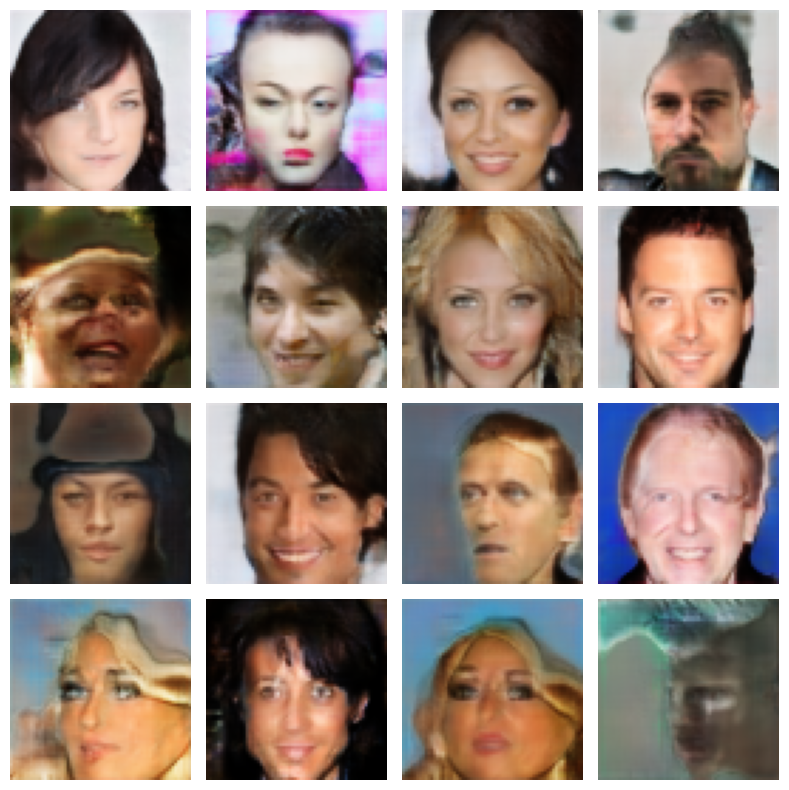

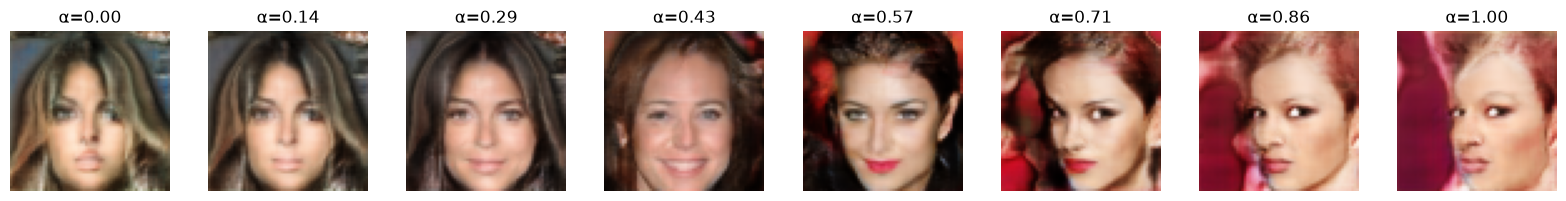

Генерация и интерполяция выполнены, результаты в TensorBoard.


In [6]:
G.eval()

# Генерация галереи
num_gen = 16
z_sample = torch.randn(num_gen, latent_dim_gan).to(device)

with torch.no_grad():
    gen_images = G(z_sample)

gen_vis = (gen_images * 0.5 + 0.5).clamp(0, 1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(np.transpose(gen_vis[i].numpy(), (1, 2, 0)))
    ax.axis('off')
plt.tight_layout()
plt.show()

# добавьте логгирование галереи в Tensorboard
# YOUR CODE IS HERE
writer_stylegan.add_image("result/gallery", make_grid(gen_vis, nrow=4), global_step)
fig.savefig(output_dir_stylegan / "stylegan_gallery.png", dpi=140, bbox_inches="tight")


# Интерполяция
num_steps_interp = 8
z1 = torch.randn(1, latent_dim_gan).to(device)
z2 = torch.randn(1, latent_dim_gan).to(device)

interp_images = []
for i, alpha in enumerate(np.linspace(0, 1, num_steps_interp)):
    z_interp = (1 - alpha) * z1 + alpha * z2
    with torch.no_grad():
        img_interp = G(z_interp)
    img_interp_vis = (img_interp * 0.5 + 0.5).clamp(0, 1).cpu()[0]
    interp_images.append(img_interp_vis)

fig, axes = plt.subplots(1, num_steps_interp, figsize=(16, 2))
for i, ax in enumerate(axes):
    ax.imshow(np.transpose(interp_images[i].numpy(), (1, 2, 0)))
    ax.axis('off')
    ax.set_title(f"α={i/(num_steps_interp-1):.2f}")
plt.tight_layout()
plt.show()

interp_stack = torch.stack(interp_images, dim=0)

# добавьте логгирование интерполяции в Tensorboard
# YOUR CODE IS HERE
writer_stylegan.add_image(
    "result/interpolation", make_grid(interp_stack, nrow=num_steps_interp), global_step,
)
fig.savefig(output_dir_stylegan / "stylegan_interpolation.png", dpi=140, bbox_inches="tight")

print('Генерация и интерполяция выполнены, результаты в TensorBoard.')

Получились ли результаты похожими на настоящие лица?

Действительно ли интерполяция плавно приближает одно лицо к другому?

Не случилось ли Mode Collapse у вашей модели?

Мы не ожидаем идеальных результатов, но ориентиром может служить наш пример:

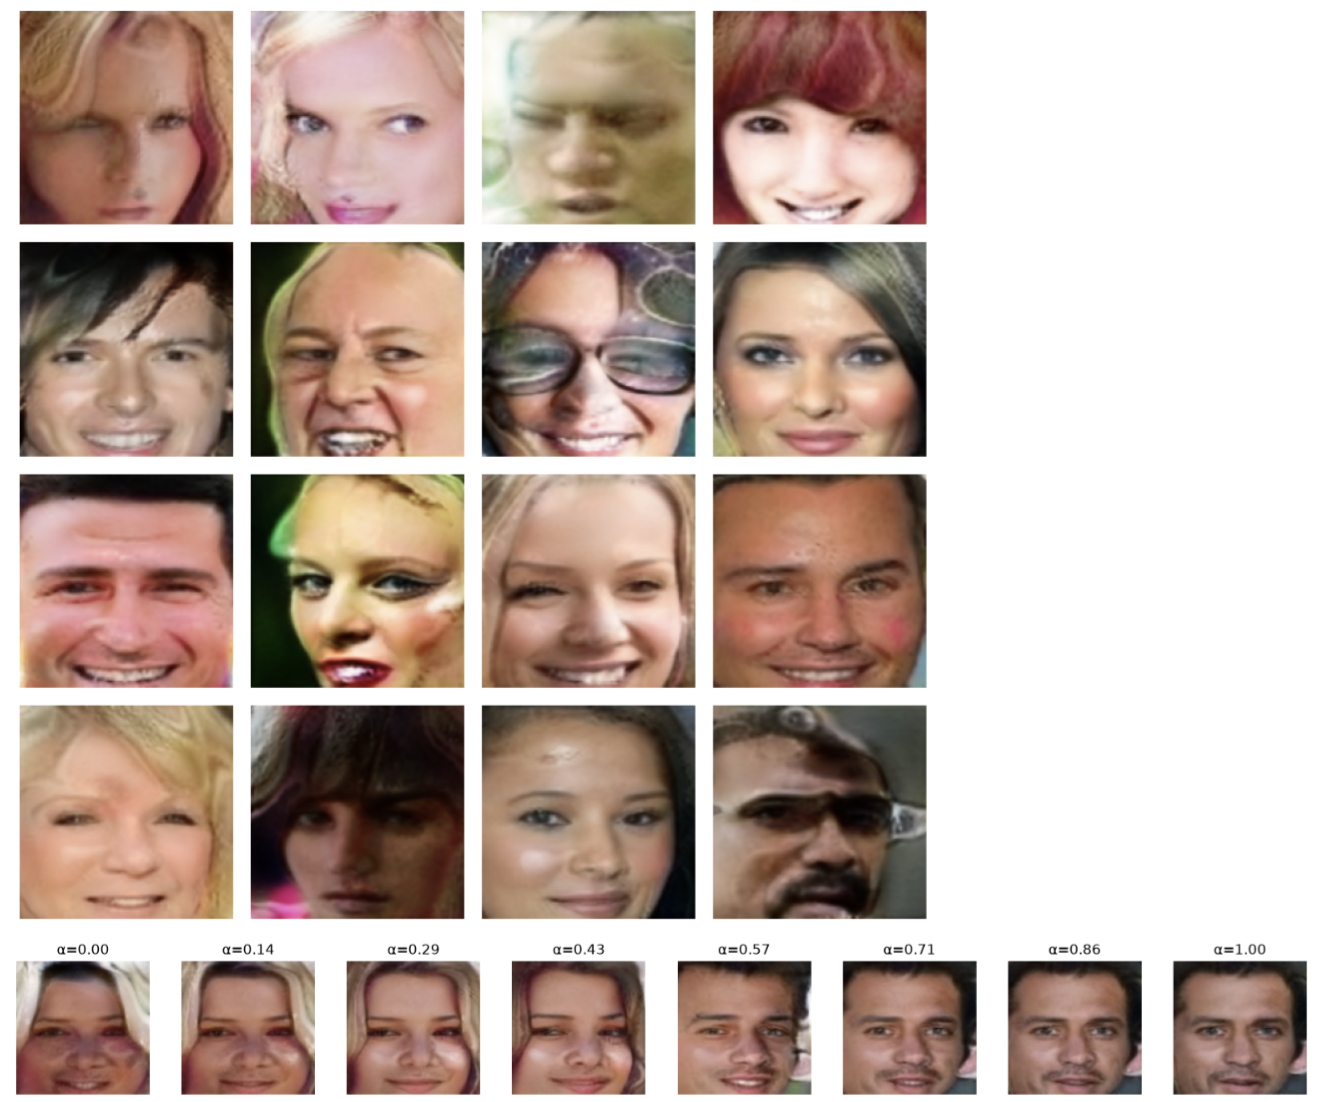

Для улучшения своих результатов мы советуем 
- поэкспериментировать с архитектурами StyleGAN-а,
- применять разные техники регуляризации,
- штрафовать модель за снижение разнообразия сэмплов,
- попробовать перечитать оригинальную статью и взять идеи оттуда: Karras et al., 2018. A Style-Based Generator Architecture for Generative Adversarial Networks. https://arxiv.org/abs/1812.04948

**Ответ.** Большинство из 16 изображений узнаются как портреты. У части лиц размыты глаза и контуры, местами заметны искажения и цветовые артефакты. При интерполяции постепенно меняются причёска, фон и ракурс, хотя выражение лица между `α=0.43` и `α=0.57` меняется заметнее, чем на соседних шагах. В галерее есть разные ракурсы, выражения и причёски, поэтому явного коллапса мод на этих примерах не видно. По 16 изображениям нельзя оценить полноту разнообразия модели.

### Часть B. Шаг 6: Style mixing (комбинирование стилей)

Что сделать: продемонстрировать style mixing (упрощённый вариант) между двумя латентными кодами.

Ожидается: примеры изображений с сочетанием признаков от разных кодов.

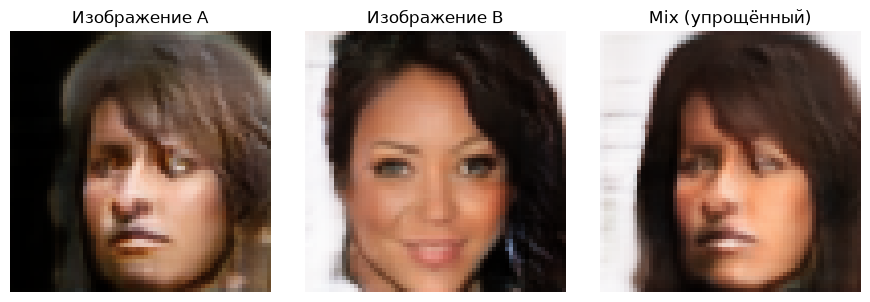

Style mixing продемонстрирован (упрощённый вариант), результаты в TensorBoard.


In [7]:
G.eval()

z_a = torch.randn(1, latent_dim_gan).to(device)
z_b = torch.randn(1, latent_dim_gan).to(device)

with torch.no_grad():
    ws_a = G.make_ws(z_a)
    ws_b = G.make_ws(z_b)

    # Ранние блоки (крупные черты: поза, форма лица) берём от A,
    # поздние (цвет, текстура, мелкие детали) — от B.
    crossover = G.num_ws // 2
    ws_mix = ws_a.clone()
    ws_mix[:, crossover:, :] = ws_b[:, crossover:, :]

    img_a = G.forward_from_ws(ws_a)
    img_b = G.forward_from_ws(ws_b)
    img_mix = G.forward_from_ws(ws_mix)

img_a_vis = (img_a * 0.5 + 0.5).clamp(0, 1).cpu()[0]
img_b_vis = (img_b * 0.5 + 0.5).clamp(0, 1).cpu()[0]
img_mix_vis = (img_mix * 0.5 + 0.5).clamp(0, 1).cpu()[0]

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(np.transpose(img_a_vis.numpy(), (1, 2, 0)))
axes[0].axis('off')
axes[0].set_title('Изображение A')
axes[1].imshow(np.transpose(img_b_vis.numpy(), (1, 2, 0)))
axes[1].axis('off')
axes[1].set_title('Изображение B')
axes[2].imshow(np.transpose(img_mix_vis.numpy(), (1, 2, 0)))
axes[2].axis('off')
axes[2].set_title('Mix (упрощённый)')
plt.tight_layout()
plt.show()

stack_style = torch.stack([img_a_vis, img_b_vis, img_mix_vis], dim=0)

# добавьте логгирование Style mixing в Tensorboard
# YOUR CODE IS HERE
writer_stylegan.add_image("result/style_mixing", make_grid(stack_style, nrow=3), global_step)
fig.savefig(output_dir_stylegan / "stylegan_style_mixing.png", dpi=140, bbox_inches="tight")
writer_stylegan.close()

print('Style mixing продемонстрирован (упрощённый вариант), результаты в TensorBoard.')

В качестве референса можно использовать этот пример:

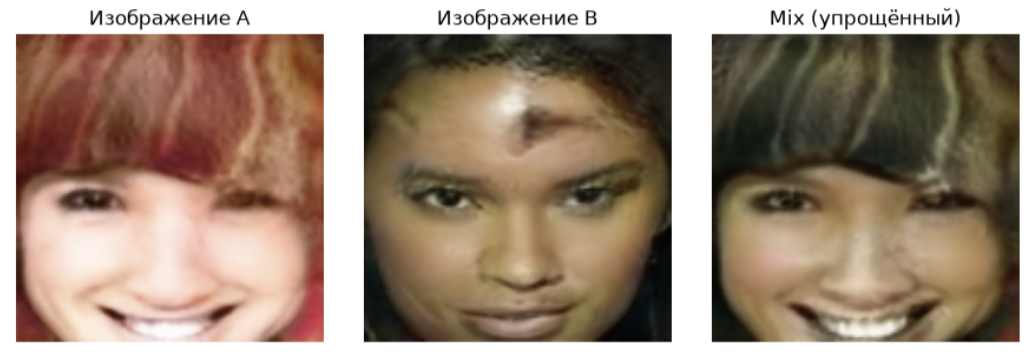

### Часть B. Шаг 7: Текстовое описание pipeline

Что сделать: кратко описать (1-2 абзаца), как вы реализовали и обучили StyleGAN-подобную модель, какие гиперпараметры использовали и какие результаты получили. Какие возникали сложности и как вы их решили, к каким источникам обращались в процессе.

Ожидается: понятное описание всей цепочки (данные - модель - обучение - визуализация)

*Ваш ответ:*

Обучал модель на 162 770 изображениях из тренировочной части CelebA. Вырезал квадрат с лицом, уменьшал его до 64×64 и нормализовал пиксели в диапазон [−1, 1]. Mapping-сеть переводит случайный вектор z в код w. Генератор начинает с обучаемого тензора 4×4, увеличивает разрешение через пять стилевых блоков и в каждом из них меняет масштаб и сдвиг каналов по своему коду w. Дискриминатор уменьшает разрешение и оценивает, похоже ли изображение на настоящее.

Чередовал обновления G и D с логистической функцией потерь. Финальный прогон длился 15 эпох (38 160 шагов), размер батча 64, seed 42, Adam с lr=0.0003 для обеих сетей и регуляризация R1 для D с γ=0.5 каждые 16 шагов. В пробном запуске с lr=0.002 лоссы сильнее колебались, а лица чаще искажались. При меньшем шаге портреты выглядят убедительнее. В примере style mixing поворот головы и чёлка ближе к A, светлый фон ближе к B. Лоссы и изображения записаны в TensorBoard.